# 08. Load vs mission

The motor power against the speed of the **mission line** (nb 04, `data/mission/mission_modes.csv`): every minute inside a line gets that line's median speed over ground. That averages out the noise (waves, current, turns, GPS), and it's the speed the forecast has.

**load = 10 W hotel + 22 W · Starlink + k_mode · v_lineⁿ**: hotel and Starlink locked (nb 06), no intercept, motor off in MANUAL (armed or disarmed). **One k for AUTO, one for mode 17.**

1. Each line on its own: propulsion vs speed, minute by minute and line by line
2. Fit per mode: k · v, k · v², k · v³ on the line speed
3. Predicting the load: real Starlink vs the Starlink plan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.figsize": (14, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_load"] = df.voltage_battery1_v * df.current_battery2_a     # W, total load

# Starlink on/off: messages < 2 min apart = one session, ± 30 s (nb 06)
direct = df[df.communication_mode == "direct"]
session_id = (direct.t.diff() > pd.Timedelta("2min")).cumsum()
sessions = direct.groupby(session_id).t.agg(start="min", end="max").reset_index(drop=True)
df["starlink"] = False
for start, end in sessions.itertuples(index=False):
    df.loc[df.t.between(start - pd.Timedelta("30s"), end + pd.Timedelta("30s")), "starlink"] = True

HOTEL_W, STARLINK_W = 10, 22                                       # nb 06, locked
SHAPES = {"k·v": 1, "k·v²": 2, "k·v³": 3}                          # motor = k · v_lineⁿ
MOTOR_MODES = ["AUTO", "mode 17"]
GROUP_NAMES = ["MANUAL disarmed", "MANUAL armed", "AUTO", "mode 17"]
GROUP_COLORS = {"MANUAL disarmed": "#c7c7c7", "MANUAL armed": "#7f7f7f", "AUTO": "#2ca02c", "mode 17": "#d62728"}
MODEL_COLORS = {"k·v": "#1f77b4", "k·v²": "#ff7f0e", "k·v³": "#9467bd"}   # standard colours, not the mode ones (green, red)
START, END = pd.Timestamp("2025-07-14", tz="UTC"), pd.Timestamp("2025-07-31", tz="UTC")

def daily_axis(ax):
    ax.set_xlim(START, END)
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# per-minute means (same as nb 07)
m = (df.dropna(subset=["P_load"]).set_index("t").resample("1min")
       .agg({"P_load": "mean", "groundspeed_ms": "mean", "starlink": "max"})
       .dropna(subset=["P_load"]).reset_index())
m["starlink"] = m.starlink.astype(bool)
m["P_prop"] = m.P_load - HOTEL_W - STARLINK_W * m.starlink

# the mission: each minute gets its line
mission = pd.read_csv("../data/mission/mission_modes.csv", parse_dates=["from", "to"])
mission["group"] = np.where(mission["mode"] == "MANUAL", np.where(mission.armed, "MANUAL armed", "MANUAL disarmed"), mission["mode"])
mission["v_line"] = mission["SOG (m/s)"]
idx = np.searchsorted(mission["from"].values, m.t.values, side="right") - 1
inside = (idx >= 0) & (m.t.values < mission["to"].values[idx.clip(0)])
m["line"] = np.where(inside, mission["#"].values[idx.clip(0)], -1)
m = m[m.line >= 0].merge(mission[["#", "group", "v_line", "hours"]], left_on="line", right_on="#").drop(columns="#")
m["motor"] = m.group.isin(["AUTO", "mode 17"]).astype(int)
print(f"{len(m)} minutes with a load reading, inside {m.line.nunique()} of {len(mission)} mission lines")
print("motor-on lines with no speed:", mission[mission.group.isin(["AUTO", "mode 17"]) & mission.v_line.isna()]["#"].tolist())

5898 minutes with a load reading, inside 90 of 105 mission lines
motor-on lines with no speed: []


## 1. Each line on its own

Motor on only (AUTO and mode 17). **Left:** what nb 07 fits, one dot per minute at its own speed. **Right:** the same minutes, but each line collapsed to **one dot**: its median speed (x) against its mean propulsion (y); dot area = minutes with a load reading. The faint dots behind are the minutes again, now placed at the line's speed (so each line is a vertical stripe).

Propulsion = load − 10 W − 22 W · Starlink (real Starlink).

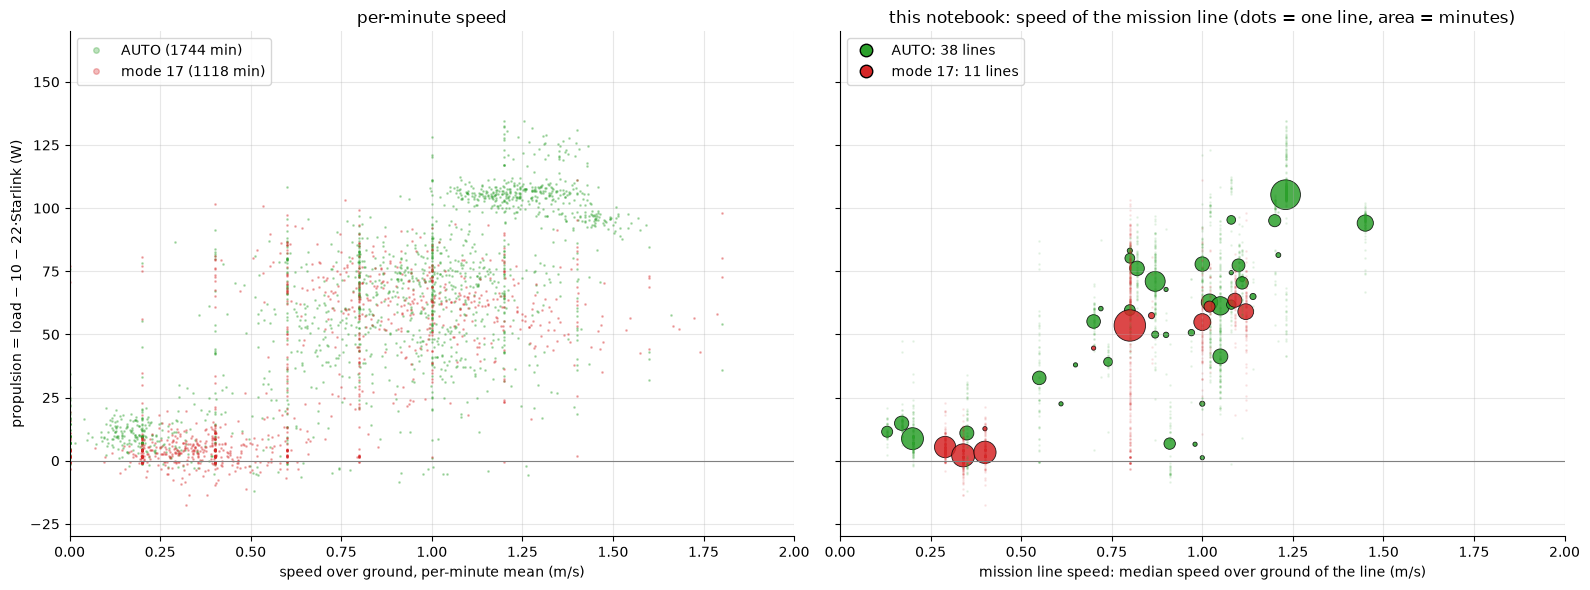

lines by speed (v_line = median speed of the line, sog_mean = mean of its minutes with a load reading):


,group,v_line,P_prop,minutes,sog_mean
line,,,,,
20,AUTO,0.13,11.48,37,0.13
26,AUTO,0.17,14.82,65,0.18
30,AUTO,0.20,8.74,161,0.20
42,mode 17,0.29,5.43,151,0.29
44,mode 17,0.34,2.12,179,0.32
66,AUTO,0.35,10.96,63,0.36
46,mode 17,0.40,3.33,166,0.40
45,mode 17,0.40,12.67,1,0.30
53,AUTO,0.55,32.79,58,0.54


In [2]:
on = m[m.motor == 1].dropna(subset=["v_line"])
per_line = on.groupby("line").agg(group=("group", "first"), v_line=("v_line", "first"), P_prop=("P_prop", "mean"),
                                  minutes=("P_prop", "size"), sog_mean=("groundspeed_ms", "mean"))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True, sharex=True)
for grp in ["AUTO", "mode 17"]:
    s = on[on.group == grp]
    a1.plot(s.groundspeed_ms, s.P_prop, ".", ms=2, alpha=0.3, color=GROUP_COLORS[grp], label=f"{grp} ({len(s)} min)")
    a2.plot(s.v_line, s.P_prop, ".", ms=2, alpha=0.08, color=GROUP_COLORS[grp])
    l = per_line[per_line.group == grp]
    a2.scatter(l.v_line, l.P_prop, s=8 + 1.5 * l.minutes, color=GROUP_COLORS[grp], edgecolor="k", lw=0.6, alpha=0.85,
               label=f"{grp}: {len(l)} lines")
for a in (a1, a2):
    a.axhline(0, color="grey", lw=0.8); a.set_xlim(0, 2); a.set_ylim(-30, 170)
a1.legend(loc="upper left", markerscale=4)
a2.legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=9, mec="k", color=GROUP_COLORS[g],
                              label=f"{g}: {(per_line.group == g).sum()} lines") for g in ["AUTO", "mode 17"]], loc="upper left")
a1.set_xlabel("speed over ground, per-minute mean (m/s)"); a2.set_xlabel("mission line speed: median speed over ground of the line (m/s)")
a1.set_ylabel("propulsion = load − 10 − 22·Starlink (W)")
a1.set_title("per-minute speed"); a2.set_title("this notebook: speed of the mission line (dots = one line, area = minutes)")
plt.tight_layout(); plt.show()
print("lines by speed (v_line = median speed of the line, sog_mean = mean of its minutes with a load reading):")
per_line.sort_values("v_line").round(2)

## 2. Fit per mode

Least squares of propulsion = load − 10 − 22 · Starlink against **v_line**ⁿ, motor-on minutes only (so a line counts by how many minutes it has), no intercept. **AUTO and mode 17 fitted separately.**

- **R² per minute:** over the minutes (each line's own wobble counts as error, since v_line is flat inside a line)
- **R² per line:** over the line means, i.e. how well the curve follows the dots

Green row = best shape for that mode, by R² per line. (The std error is the uncertainty of k in its own units, which change with the shape, so it can't compare shapes.)

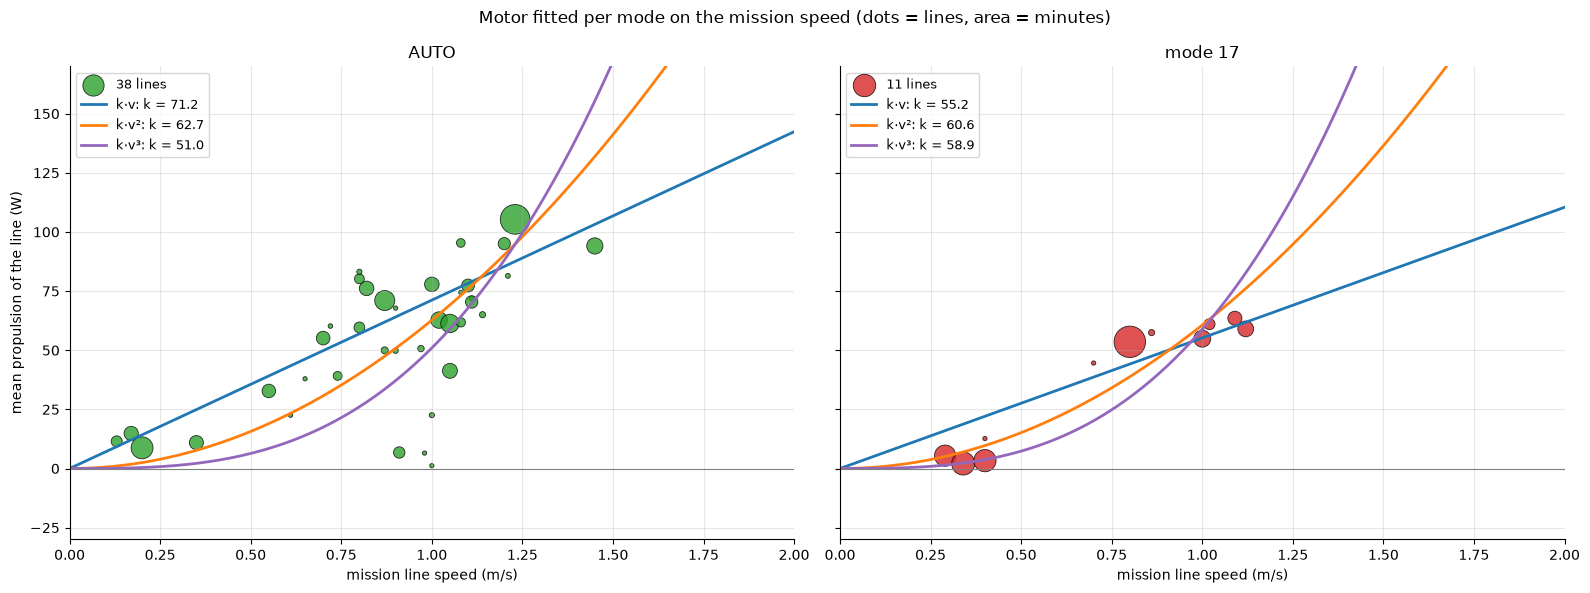

In [3]:
on["mode"] = on.group
per_line["mode"] = per_line.group
rows, K_MODE = [], {}
for grp in MOTOR_MODES:
    s = on[on["mode"] == grp]; ys = s.P_prop.values
    pls = per_line[per_line["mode"] == grp]; w = pls.minutes
    for name, n in SHAPES.items():
        X = s.v_line.values ** n
        kn = (X * ys).sum() / (X ** 2).sum()
        r = ys - kn * X
        pl = pls.P_prop - kn * pls.v_line ** n
        K_MODE[(grp, name)] = kn
        rows.append({"mode": grp, "model": name, "k": kn, "std error": np.sqrt((r ** 2).sum() / (len(ys) - 1) / (X ** 2).sum()),
                     "minutes": len(ys), "lines": len(pls), "mean residual (W)": r.mean(),
                     "R² per minute": 1 - (r ** 2).sum() / ((ys - ys.mean()) ** 2).sum(),
                     "R² per line": 1 - (w * pl ** 2).sum() / (w * (pls.P_prop - np.average(pls.P_prop, weights=w)) ** 2).sum()})
fit_table = pd.DataFrame(rows).set_index(["mode", "model"])
best = set(fit_table.groupby(level="mode")["R² per line"].idxmax())          # best shape per mode, by R² over the line means
display(fit_table.style.format("{:.2f}", subset=fit_table.columns.drop(["minutes", "lines"]))
        .apply(lambda r: ["background-color: #c7e9c0" if r.name in best else ""] * len(r), axis=1))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
vv = np.linspace(0, 2, 200)
for ax, grp in zip(axes, MOTOR_MODES):
    l = per_line[per_line["mode"] == grp]
    ax.scatter(l.v_line, l.P_prop, s=8 + 1.5 * l.minutes, color=GROUP_COLORS[grp], edgecolor="k", lw=0.6, alpha=0.8, label=f"{len(l)} lines")
    for name, n in SHAPES.items():
        kn = K_MODE[(grp, name)]
        ax.plot(vv, kn * vv ** n, lw=2, color=MODEL_COLORS[name], label=f"{name}: k = {kn:.1f}")
    ax.axhline(0, color="grey", lw=0.8); ax.set_xlim(0, 2); ax.set_ylim(-30, 170)
    ax.set_title(grp); ax.set_xlabel("mission line speed (m/s)"); ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("mean propulsion of the line (W)")
fig.suptitle("Motor fitted per mode on the mission speed (dots = lines, area = minutes)")
plt.tight_layout(); plt.show()

## 3. Predicting the load

**k·v² per mode** (the shape the forecast uses, for both modes), mission line speed, scored per minute. Error = actual − predicted.

| prediction | Starlink |
| --- | --- |
| **real Starlink** | 1 inside a real session |
| **Starlink plan** | the plan (nb 05): what the forecast uses |

In [4]:
sl_plan = pd.read_csv("../data/mission/mission_starlink.csv", parse_dates=["from", "to"]).rename(columns={"from": "start"})   # one row per session (nb 05)
def starlink_schedule(ts):
    ts = pd.DatetimeIndex(ts); sl = np.zeros(len(ts))
    for r in sl_plan.itertuples():   # share of each minute [t, t + 1 min) inside a session window
        sl += np.clip((np.minimum(ts + pd.Timedelta("1min"), r.to) - np.maximum(ts, r.start)).total_seconds() / 60, 0, 1)
    return sl

m["sl_plan"] = starlink_schedule(m.t)
v_line = m.v_line.fillna(0).values
USE_SHAPE = "k·v²"                                                  # the forecast (nb 12) uses k·v² for both modes
k_by_min = np.select([m.group == g for g in MOTOR_MODES], [K_MODE[(g, USE_SHAPE)] for g in MOTOR_MODES], 0.0)
motor_W = m.motor * k_by_min * v_line ** SHAPES[USE_SHAPE]
print(f"{USE_SHAPE}: " + ", ".join(f"k {g} = {K_MODE[(g, USE_SHAPE)]:.1f}" for g in MOTOR_MODES))
PRED = {"real Starlink": HOTEL_W + STARLINK_W * m.starlink + motor_W,
        "Starlink plan": HOTEL_W + STARLINK_W * m.sl_plan + motor_W}
PRED_STYLE = {"real Starlink": dict(color="#1f77b4", lw=1.5), "Starlink plan": dict(color="#d62728", lw=1.5, ls="--")}

def scores(e):
    return pd.Series({"mean error (W)": e.mean(), "RMSE (W)": np.sqrt((e ** 2).mean()), "median |error| (W)": e.abs().median(), "max |error| (W)": e.abs().max()})
errs = {n: m.P_load - p for n, p in PRED.items()}
print(f"{len(m)} minutes")
display(pd.DataFrame({n: scores(e) for n, e in errs.items()}).T.round(1))
print("by mode:")
pd.concat({"mean error (W)": pd.DataFrame({n: e.groupby(m.group).mean() for n, e in errs.items()}),
           "RMSE (W)": pd.DataFrame({n: e.groupby(m.group).apply(lambda x: np.sqrt((x ** 2).mean())) for n, e in errs.items()})}).reindex(GROUP_NAMES, level=1).round(1)

k·v²: k AUTO = 62.7, k mode 17 = 60.6
5898 minutes


,mean error (W),RMSE (W),median |error| (W),max |error| (W)
real Starlink,2.0,16.8,5.5,97.0
Starlink plan,2.1,16.8,5.5,100.3


by mode:


real Starlink  Starlink plan
               group                                        
mean error (W) MANUAL disarmed            0.3            0.4
               MANUAL armed               1.3            1.4
               AUTO                       4.5            4.7
               mode 17                    0.6            0.9
RMSE (W)       MANUAL disarmed            6.1            6.1
               MANUAL armed               9.7            9.7
               AUTO                      23.4           23.5
               mode 17                   20.1           20.1

**Over the mission.** Hourly means of the measured load (black) and the main predictions. Bottom: per line, mean error of each prediction (one dot per motor-on line, at the line's start).

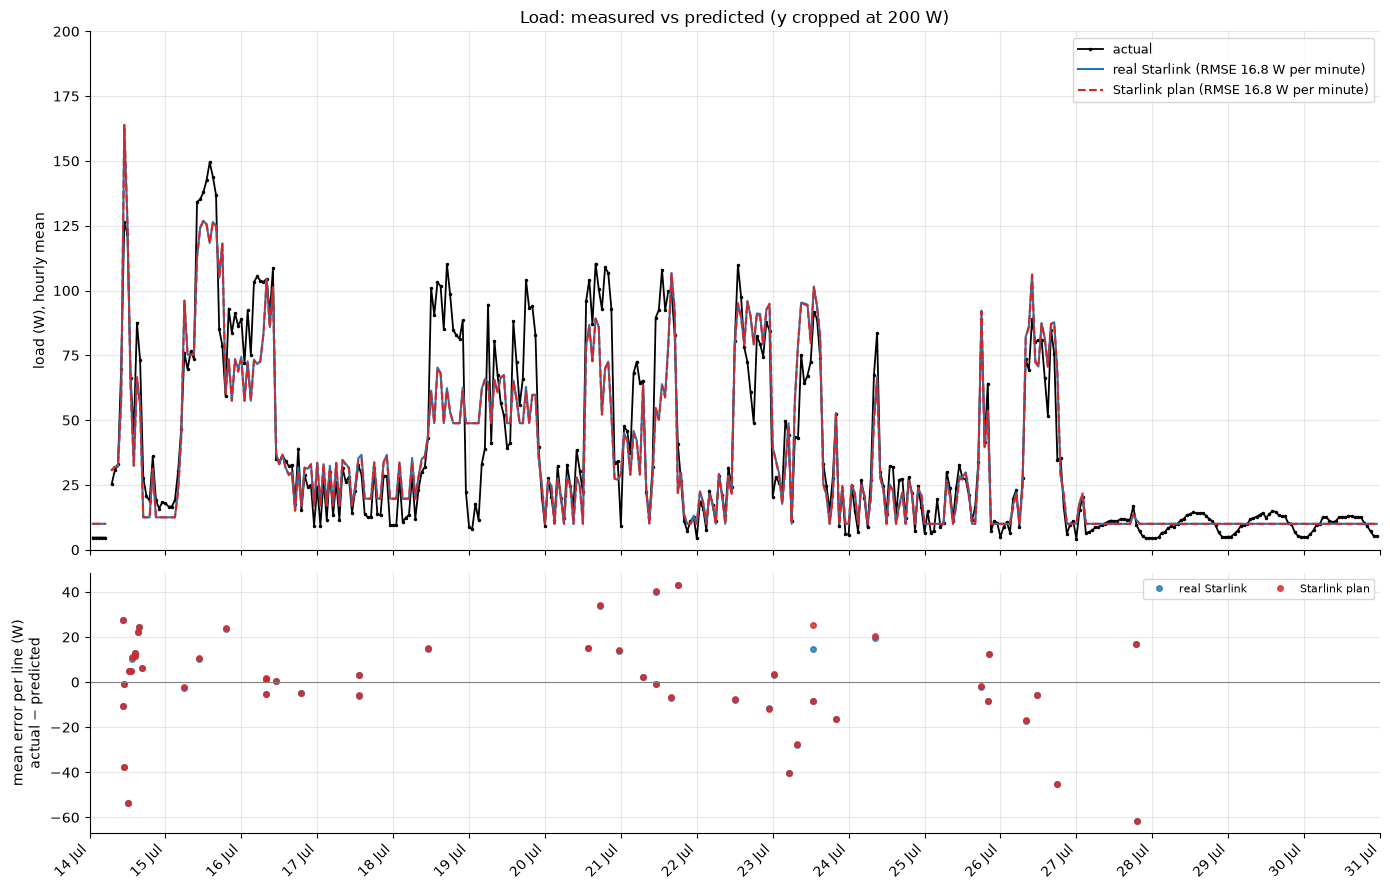

t,14 Jul,15 Jul,16 Jul,17 Jul,18 Jul,19 Jul,20 Jul,21 Jul,22 Jul,23 Jul,24 Jul,25 Jul,26 Jul,27 Jul,28 Jul,29 Jul,30 Jul
actual,66.0,107.0,60.0,25.0,68.0,59.0,66.0,51.0,45.0,50.0,30.0,35.0,53.0,9.0,10.0,10.0,10.0
real Starlink,63.0,98.0,53.0,30.0,50.0,57.0,52.0,45.0,48.0,57.0,27.0,33.0,62.0,11.0,10.0,10.0,10.0
Starlink plan,63.0,98.0,53.0,30.0,50.0,56.0,51.0,45.0,48.0,57.0,26.0,33.0,62.0,11.0,10.0,10.0,10.0


In [5]:
hh = pd.concat([m.set_index("t").P_load] + [p.set_axis(m.t).rename(n) for n, p in PRED.items() if n in PRED_STYLE], axis=1).resample("1h").mean()
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax.plot(hh.index, hh.P_load, ".-", ms=3, lw=1.3, color="k", label="actual")
for n, st in PRED_STYLE.items():
    ax.plot(hh.index, hh[n], label=f"{n} (RMSE {np.sqrt((errs[n] ** 2).mean()):.1f} W per minute)", **st)
ax.set_ylim(0, 200); ax.set_ylabel("load (W), hourly mean"); ax.legend(fontsize=9, loc="upper right")
ax.set_title("Load: measured vs predicted (y cropped at 200 W)")
starts = mission.set_index("#")["from"]
for n, st in PRED_STYLE.items():
    le = errs[n][m.motor == 1].groupby(m.line[m.motor == 1]).mean()
    ax2.plot(starts.reindex(le.index), le.values, "o", ms=4, color=st["color"], alpha=0.8, label=n)
ax2.axhline(0, color="grey", lw=0.8); ax2.set_ylabel("mean error per line (W)\nactual − predicted")
ax2.legend(fontsize=8, ncol=4, loc="upper right")
daily_axis(ax2)
plt.tight_layout(); plt.show()

d = pd.concat([m.P_load] + [p.rename(n) for n, p in PRED.items() if n in PRED_STYLE], axis=1).groupby(m.t.dt.floor("D")).mean()
d.set_axis(d.index.strftime("%d %b")).rename(columns={"P_load": "actual"}).round(0).T